In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
print("Scikit-learn version:", sklearn.__version__)


Scikit-learn version: 1.6.1


In [22]:
df = pd.read_csv("/content/heart.csv")

In [23]:
df = df.drop_duplicates()

# Replace infinite values with missing values
df = df.replace([np.inf, -np.inf], np.nan)

# Remove rows with missing target values
df = df.dropna(subset=["target"])

# Separate features and target
X = df.drop("target", axis=1)
y = df["target"]

# Fill missing feature values with column medians
X = X.fillna(X.median(numeric_only=True))

print("Preprocessing completed!")
print("Dataset shape:", df.shape)
print("Missing values:", X.isnull().sum())
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print(df.head())

Preprocessing completed!
Dataset shape: (302, 14)
Missing values: age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
dtype: int64
Features shape: (302, 13)
Target shape: (302,)
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   52    1   0       125   212    0        1      168      0      1.0      2   
1   53    1   0       140   203    1        0      155      1      3.1      0   
2   70    1   0       145   174    0        1      125      1      2.6      0   
3   61    1   0       148   203    0        1      161      0      0.0      2   
4   62    0   0       138   294    1        1      106      0      1.9      1   

   ca  thal  target  
0   2     3       0  
1   0     3       0  
2   0     3       0  
3   1     3       0  
4   3     2       0  


In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Training samples:",len(y_train))
print("Testing samples:", len(y_test))

Training samples: 241
Testing samples: 61
Training samples: 241
Testing samples: 61


In [25]:
# Fill missing values with training-set medians
imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

# Scale the features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("Missing-value handling completed.")
print("Feature scaling completed.")

Missing-value handling completed.
Feature scaling completed.


In [26]:
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model.fit(X_train_scaled, y_train)

print("Model trained successfully!")

Model trained successfully!


In [27]:
y_pred = model.predict(X_test_scaled)
accuracy = accuracy_score(y_test, y_pred)
print(f"Test accuracy: {accuracy * 100:.2f}%")

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["No heart disease", "Heart disease"],
))

Test accuracy: 80.33%

Classification report:
                  precision    recall  f1-score   support

No heart disease       0.81      0.75      0.78        28
   Heart disease       0.80      0.85      0.82        33

        accuracy                           0.80        61
       macro avg       0.80      0.80      0.80        61
    weighted avg       0.80      0.80      0.80        61



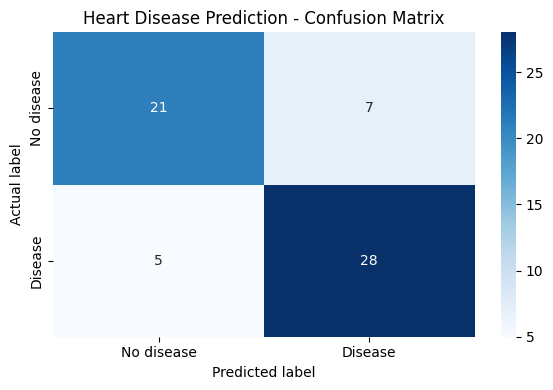

In [28]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No disease", "Disease"],
    yticklabels=["No disease", "Disease"]
)

plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("Heart Disease Prediction - Confusion Matrix")
plt.tight_layout()
plt.show()

In [29]:
sample = X_test.iloc[[0]]

sample_scaled = scaler.transform(
    imputer.transform(sample)
)

prediction = int(model.predict(sample_scaled)[0])
probabilities = model.predict_proba(sample_scaled)[0]

print("Predicted class:", prediction)

if prediction == 1:
    print("Model output: Positive class")
else:
    print("Model output: Negative class")

print("\nModel class probabilities:")
for label, probability in zip(model.classes_, probabilities):
    print(f"Class {label}: {probability:.2%}")

Predicted class: 0
Model output: Negative class

Model class probabilities:
Class 0: 81.46%
Class 1: 18.54%


In [30]:
artifact = {
    "model": model,
    "imputer": imputer,
    "scaler": scaler,
    "columns": X.columns.tolist()
}

joblib.dump(artifact, "heart_disease_model.pkl")

files.download("heart_disease_model.pkl")

print("Model saved successfully!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Model saved successfully!
